In [ ]:
!nvidia-smi

Wed Oct 21 12:15:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import numpy as np
import time

N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)

start = time.time()
C_cpu = np.matmul(A_cpu, B_cpu)
end = time.time()

print(f"Mnożenie macierzy na CPU trwało: {end - start:.5f} sekund.")

Mnożenie macierzy na CPU trwało: 0.02623 sekund.


In [ ]:
import cupy as cp
import time

N = [1000, 3000, 5000, 7000, 10000]
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)

A_gpu = cp.array(A_cpu)
B_gpu = cp.array(B_cpu)

start = time.time()
C_gpu = cp.matmul(A_gpu, B_gpu)
cp.cuda.Stream.null.synchronize()
end = time.time()

del A_gpu
del B_gpu
del C_gpu

print(f"Mnożenie macierzy na GPU trwało: {end - start:.5f} sekund.")

In [ ]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"
!pip install pycuda

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 32.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.8/101.8 kB 13.1 MB/s eta 0:00:00


In [ ]:
import pycuda.driver as cuda
from pycuda.compiler import SourceModule

cuda.init()
pycuda_ctx = cuda.Device(0).retain_primary_context()
pycuda_ctx.push()

kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    float sum = 0.0;
    if (row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""

mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
C_cpu = np.empty((N, N), np.float32)

A_gpu = cuda.mem_alloc(A_cpu.nbytes)
B_gpu = cuda.mem_alloc(B_cpu.nbytes)
C_gpu = cuda.mem_alloc(C_cpu.nbytes)

cuda.memcpy_htod(A_gpu, A_cpu)
cuda.memcpy_htod(B_gpu, B_cpu)

block_size = (32, 32, 1)
grid_size = (int(N/32), int(N/32), 1)

start = time.time()
matrixMul(A_gpu, B_gpu, C_gpu, np.int32(N), block=block_size, grid=grid_size)
cuda.Context.synchronize()
end = time.time()
print(f"Matrix size: {N} | GPU kernel CUDA time: {end - start:.5f} s")

cuda.memcpy_dtoh(C_cpu, C_gpu)

del A_gpu
del B_gpu
del C_gpu
pycuda_ctx.pop()

Matrix size: 1024 | GPU kernel CUDA time: 0.00701 s


Satrt pomiaru wydajności...

--- Test dla N = 1000 ---
  CPU NumPy:       0.0200 s
  GPU CuPy:        0.0011 s
  GPU CUDA : 0.0065 s

--- Test dla N = 3000 ---
  CPU NumPy:       0.5334 s
  GPU CuPy:        0.0220 s
  GPU CUDA : 0.1736 s

--- Test dla N = 5000 ---
  CPU NumPy:       2.2310 s
  GPU CuPy:        0.0944 s
  GPU CUDA : 0.5048 s

--- Test dla N = 7000 ---
  CPU NumPy:       6.1616 s
  GPU CuPy:        0.2516 s
  GPU CUDA : 1.2808 s

--- Test dla N = 9000 ---
  CPU NumPy:       14.0011 s
  GPU CuPy:        0.4406 s
  GPU CUDA : 2.8122 s



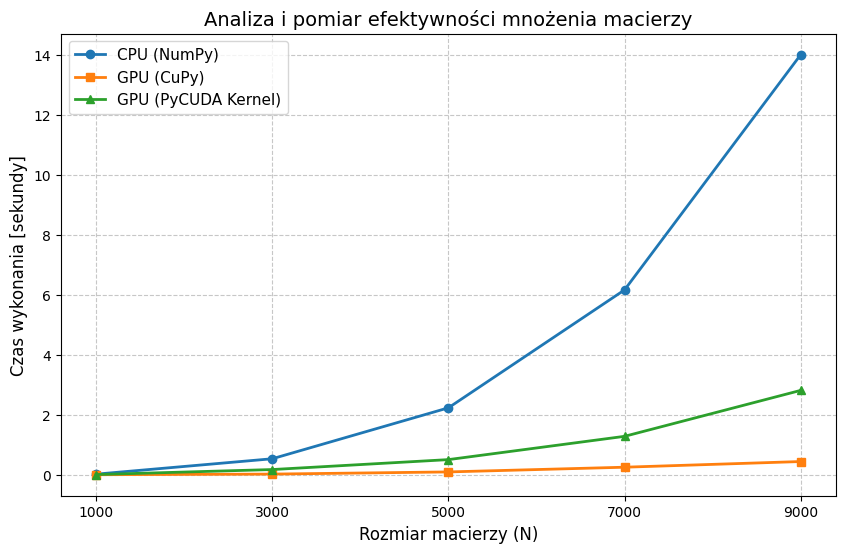

In [ ]:
import matplotlib.pyplot as plt
import pycuda.driver as cuda

cuda.init()
ctx = cuda.Device(0).retain_primary_context()
ctx.push()

kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    float sum = 0.0;
    if (row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""
mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

sizes = [1000, 3000, 5000, 7000, 9000]

cpu_times = []
cupy_times = []
pycuda_times = []

print("Satrt pomiaru wydajności...\n")

for N in sizes:
    print(f"--- Test dla N = {N} ---")

    A_cpu = np.random.rand(N, N).astype(np.float32)
    B_cpu = np.random.rand(N, N).astype(np.float32)

    # --- Pomiar CPU (NumPy) ---
    start = time.time()
    _ = np.matmul(A_cpu, B_cpu)
    end = time.time()
    t_cpu = end - start
    cpu_times.append(t_cpu)
    print(f"  CPU NumPy:       {t_cpu:.4f} s")

    # --- Pomiar GPU CuPy ---
    A_gpu_cp = cp.array(A_cpu)
    B_gpu_cp = cp.array(B_cpu)

    start = time.time()
    _ = cp.matmul(A_gpu_cp, B_gpu_cp)
    cp.cuda.Stream.null.synchronize()
    end = time.time()
    t_cupy = end - start
    cupy_times.append(t_cupy)
    print(f"  GPU CuPy:        {t_cupy:.4f} s")

    del A_gpu_cp, B_gpu_cp
    cp.get_default_memory_pool().free_all_blocks()

    # --- Pomiar GPU CUDA ---
    C_cpu = np.empty((N, N), np.float32)

    A_gpu_cuda = cuda.mem_alloc(A_cpu.nbytes)
    B_gpu_cuda = cuda.mem_alloc(B_cpu.nbytes)
    C_gpu_cuda = cuda.mem_alloc(C_cpu.nbytes)

    cuda.memcpy_htod(A_gpu_cuda, A_cpu)
    cuda.memcpy_htod(B_gpu_cuda, B_cpu)

    block_size = (32, 32, 1)
    grid_x = int(np.ceil(N / 32))
    grid_y = int(np.ceil(N / 32))
    grid_size = (grid_x, grid_y, 1)

    start = time.time()
    matrixMul(A_gpu_cuda, B_gpu_cuda, C_gpu_cuda, np.int32(N), block=block_size, grid=grid_size)
    cuda.Context.synchronize()
    end = time.time()
    t_pycuda = end - start
    pycuda_times.append(t_pycuda)
    print(f"  GPU CUDA : {t_pycuda:.4f} s\n")

    del A_gpu_cuda, B_gpu_cuda, C_gpu_cuda

# --- Wykres ---
plt.figure(figsize=(10, 6))

plt.plot(sizes, cpu_times, marker='o', linewidth=2, label="CPU (NumPy)")
plt.plot(sizes, cupy_times, marker='s', linewidth=2, label="GPU (CuPy)")
plt.plot(sizes, pycuda_times, marker='^', linewidth=2, label="GPU (PyCUDA Kernel)")

plt.title("Analiza i pomiar efektywności mnożenia macierzy", fontsize=14)
plt.xlabel("Rozmiar macierzy (N)", fontsize=12)
plt.ylabel("Czas wykonania [sekundy]", fontsize=12)
plt.xticks(sizes)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(fontsize=11)

plt.show()